In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "4" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch04_make_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 4.1 make入門 (`Introduction to Make & Bare-metal Build Automation`)

本節では、名著『ゼロからのOS自作入門』第4章の幕開けとなる **`make` によるビルド自動化** の動作原理と、MikanOS 公式リポジトリのタグ **`osbook_day04a`** で導入されたカーネルビルドファイル `kernel/Makefile` の全容を徹底解剖します。

---

## 🎯 なぜ OS カーネル開発において `make` が不可欠なのか？（動機と課題）

第3章（`osbook_day03d`）まで、私たちはカーネルのコンパイルとリンクを次のようにシェルのコマンドラインから毎回手動で実行するか、あるいは単純なシェルスクリプトに頼っていました：

```bash
# 第3章までのカーネルビルド手順（手動またはシェルスクリプト）
clang++ -O2 -Wall -g --target=x86_64-elf -ffreestanding -mno-red-zone \
        -fno-exceptions -fno-rtti -std=c++17 -c main.cpp
ld.lld --entry KernelMain -z norelro --image-base 0x100000 --static -o kernel.elf main.o
```

この方法には、OS開発が本格化するにつれて **致命的な限界と課題** が生じます：

1. **複数ファイル化に伴う再コンパイル時間の爆発**:
   - 第4章以降、カーネルのソースコードは `graphics.cpp`（ピクセル描画）、`font.cpp`（フォント展開）、`console.cpp`（ターミナル制御）、`pci.cpp`（PCIバス走査）、`interrupt.cpp`（割り込み）と急速に分割・肥大化していきます。
   - シェルスクリプトで毎回すべての `.cpp` ファイルをゼロからコンパイル（フルビルド）していると、たった1行のコメントや描画色の変更をテストするだけでも数十秒〜数分の待ち時間が発生し、開発のリズム（OODAループ）が完全に崩壊します。
2. **手動打ち込みによる人為的ミス（Human Error）**:
   - ベアメタル環境向けのコンパイルフラグ（`-ffreestanding`, `-mno-red-zone` 等）やリンカフラグ（`--entry KernelMain`, `--image-base 0x100000`）は非常に長く複雑です。1文字でもタイポしたりフラグを忘れたりすると、生成されたバイナリがサイレントにクラッシュしたり、ブートローダが不正アドレスへジャンプして即座にTriple Faultを引き起こします。
3. **インクリメンタルビルド（*Incremental Build*）の必然性**:
   - 変更されたソースコードファイルと、それに依存するオブジェクトファイル・最終実行ファイル **のみ** を自動的に検知して最小限のコマンドだけを再実行するツール、それが **`make`** です。


## 1. `Makefile` の基本構造と MikanOS Day 04a の全容

`make` コマンドが読み込む設定ファイルを **`Makefile`**（または `makefile`）と呼びます。

### 1.1 基本構文（Target, Prerequisites, Recipe）

Makefile は基本的に以下の「ルール（*Rule*）」の集まりで構成されます：

```makefile
ターゲット (Target): 必須条件 (Prerequisites / Dependencies)...
	レシピ (Recipe / Commands)...
```

- **ターゲット (*Target*)**: 作成したいファイル名（例: `kernel.elf`, `main.o`）、または実行したい処理名（例: `all`, `clean`）。
- **必須条件 (*Prerequisites / Dependencies*)**: ターゲットを作成するために必要なファイルの一覧（例: `main.cpp`, `Makefile`）。
- **レシピ (*Recipe*)**: ターゲットを生成するために実行するシェルコマンド。
  > [!CAUTION]
  > **タブ文字（Tab）の絶対的規則**: レシピの行頭は **必ず「タブ文字 (`\t`)」** でなければなりません。スペース4個や8個でインデントすると、GNU Make は `*** missing separator. Stop.` というエラーを吐いて停止します。

---

### 1.2 `osbook_day04a` の `kernel/Makefile` の全コード

MikanOS の `kernel/` ディレクトリに初めて配置された `Makefile` は以下の通りです：

```makefile
TARGET = kernel.elf
OBJS = main.o

CXXFLAGS += -O2 -Wall -g --target=x86_64-elf -ffreestanding -mno-red-zone \
            -fno-exceptions -fno-rtti -std=c++17
LDFLAGS  += --entry KernelMain -z norelro --image-base 0x100000 --static

.PHONY: all
all: $(TARGET)

.PHONY: clean
clean:
	rm -rf *.o

kernel.elf: $(OBJS) Makefile
	ld.lld $(LDFLAGS) -o kernel.elf $(OBJS)

%.o: %.cpp Makefile
	clang++ $(CPPFLAGS) $(CXXFLAGS) -c $<
```

---

### 1.3 擬似ターゲット（*Phony Target*: `.PHONY`）の真の意義

Makefile の先頭付近に書かれている `.PHONY: all` と `.PHONY: clean` は、**「このターゲットは実体ファイルではない」** ことを `make` に宣言する重要なディレクティブです。

- **なぜ必要なのか？（ファイル名衝突の罠）**:
  - もしカレントディレクトリに偶然 `clean` という名前のディレクトリやファイルが存在した場合、`.PHONY: clean` が無いと、Make はファイルシステム上の `clean` ファイルのタイムスタンプを確認します。
  - `clean` ターゲットには必須条件（Prerequisites）が指定されていないため、「依存ファイルがなくターゲット `clean` が既に存在する」＝「`clean` は最新である」と判断され、**`make clean` を実行しても `rm -rf *.o` が一切実行されなくなる** という深刻なバグに陥ります。
  - `.PHONY: clean` と明記することで、同名ファイルが存在するかどうかにかかわらず、**常に無条件でレシピを実行** させることができます。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:15224: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


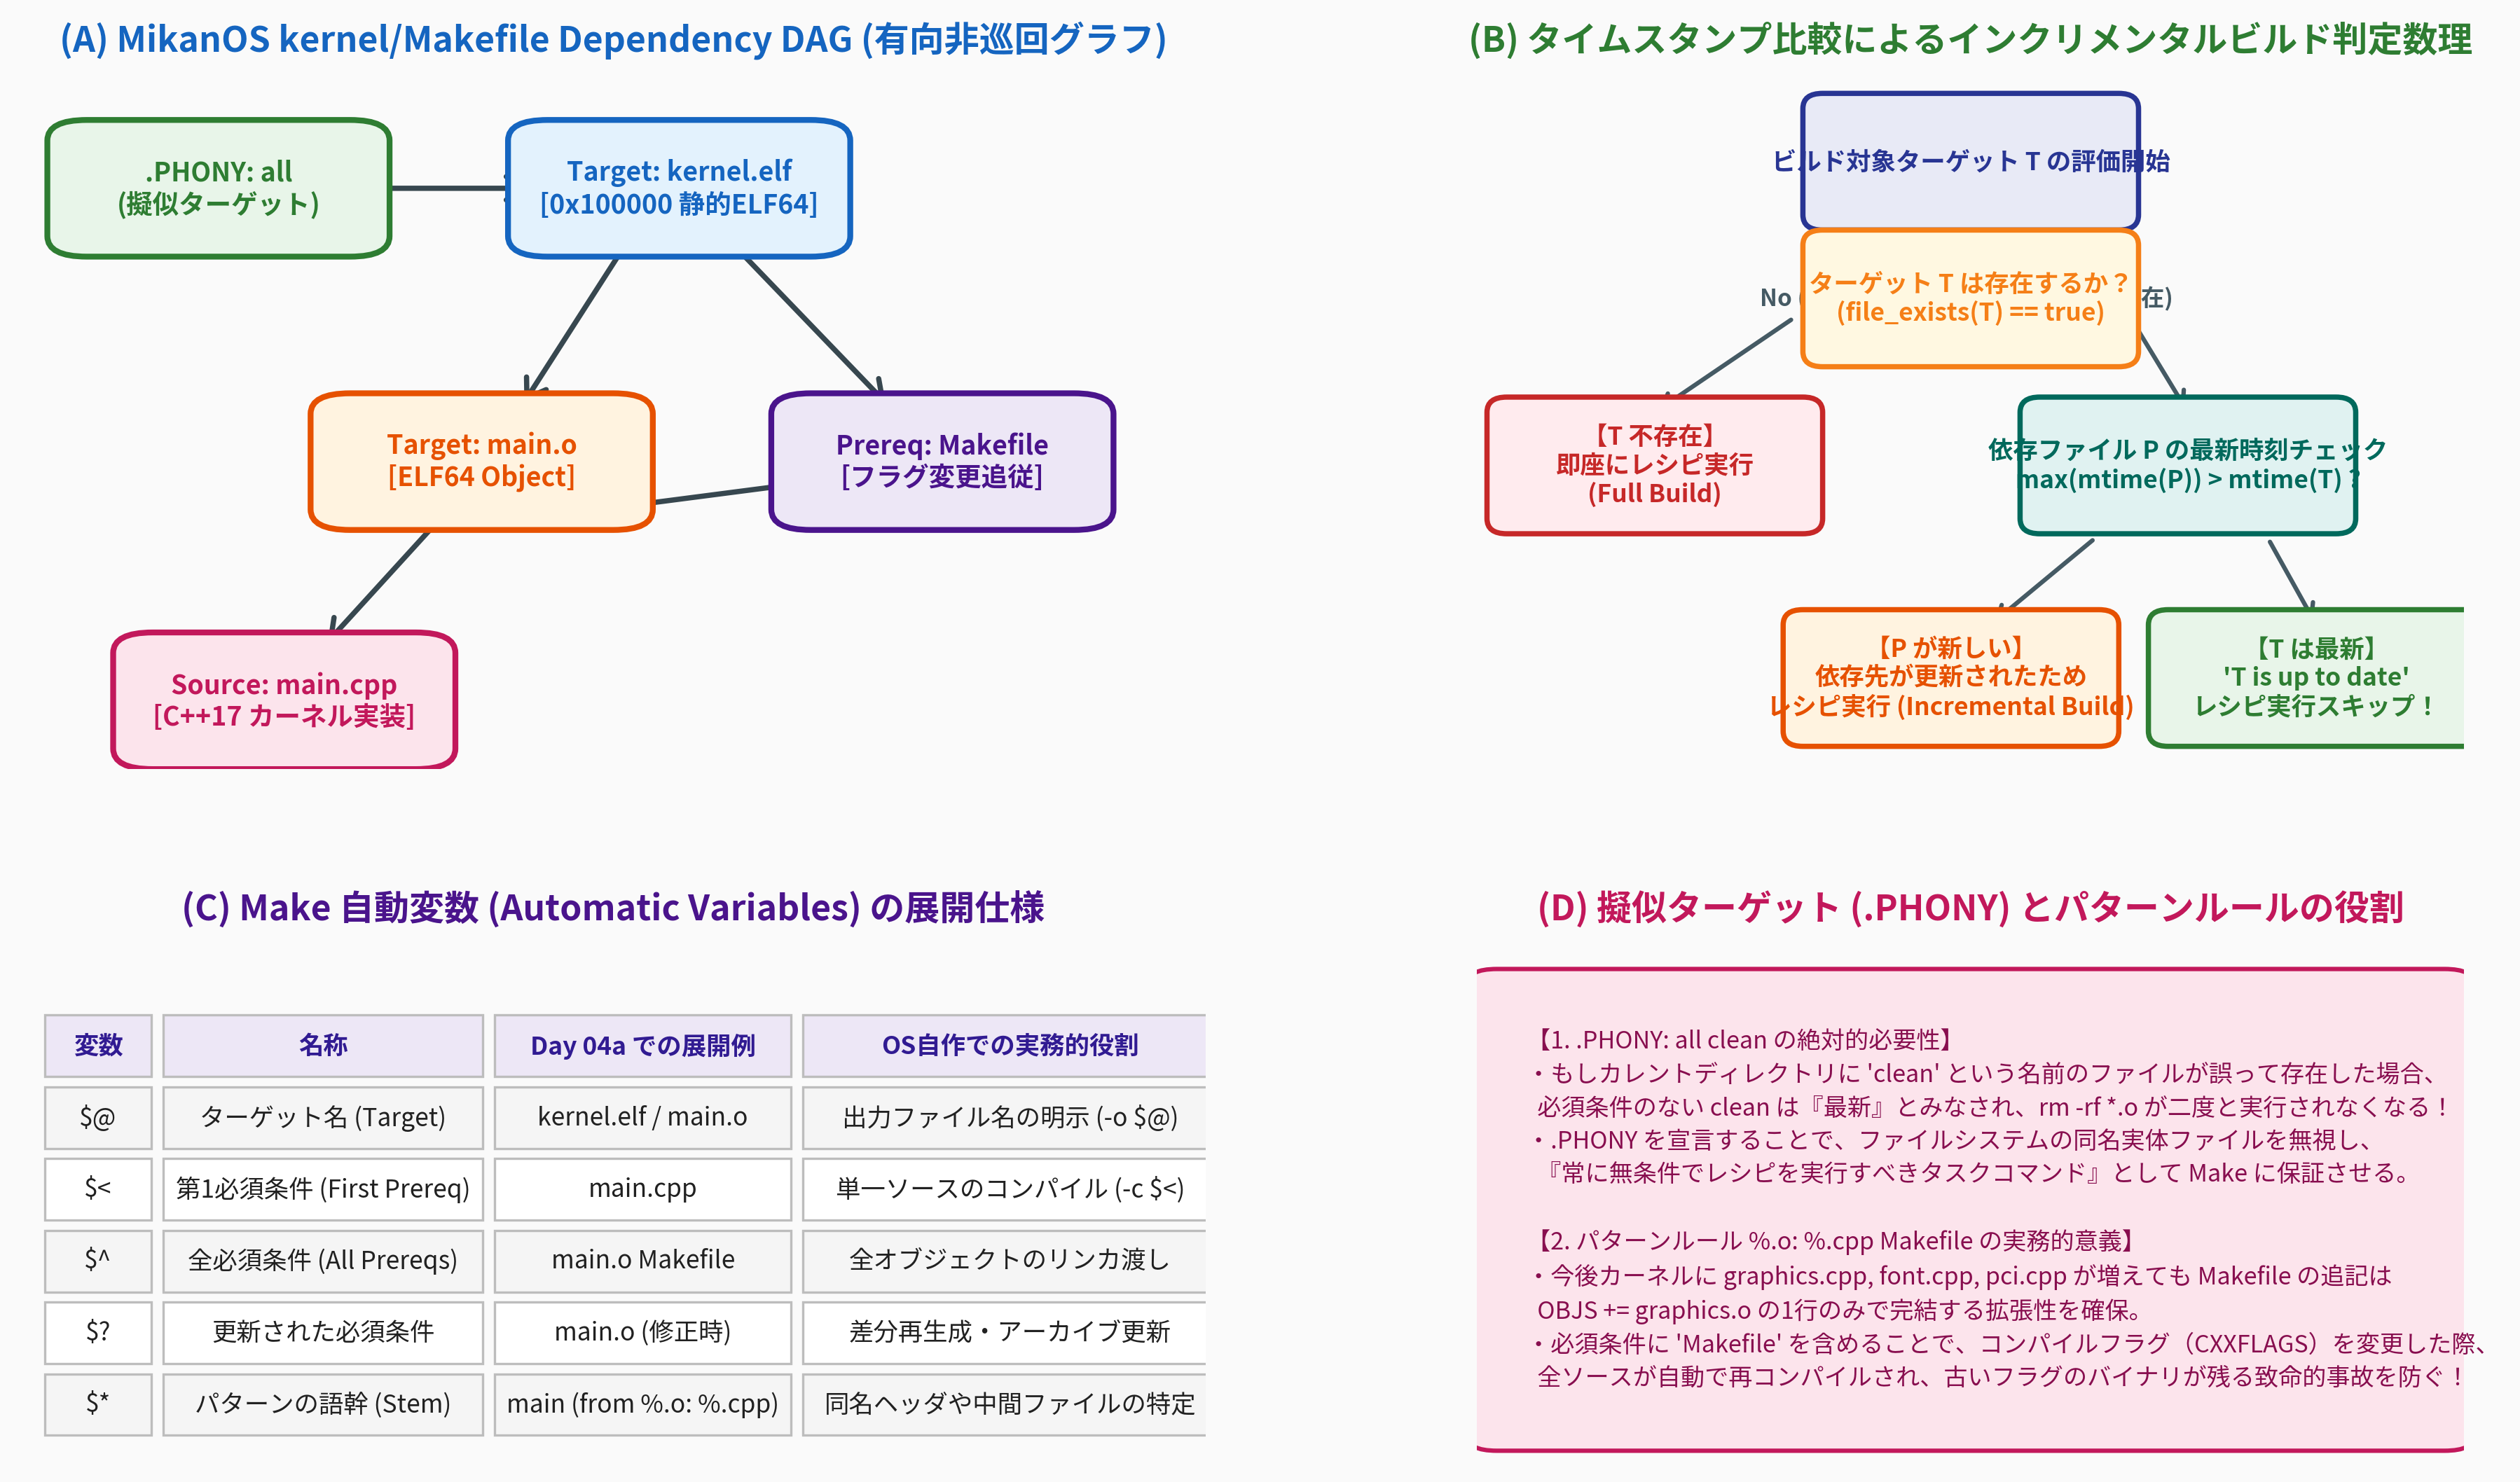

In [2]:
# === Figure 4-1: Makefile 依存関係 DAG とタイムスタンプ評価数理の可視化 ===
import os
from common import (
    plot_fig4_01_make_dag_and_timestamp_evaluation,
    plot_fig4_02_compiler_and_linker_flag_architecture
)
from IPython.display import Image, display

fig4_01_path = os.path.join(repo_root, "4/result/fig4_01_make_dag_and_timestamp_evaluation.png")
plot_fig4_01_make_dag_and_timestamp_evaluation(fig4_01_path)
display(Image(filename=fig4_01_path, width=950))


## 2. ファイル依存関係グラフ（DAG）とトポロジカルソートの数理

Make がインクリメンタルビルドを正確に実行できるのは、Makefile に記述されたルールから **有向非巡回グラフ（DAG: *Directed Acyclic Graph*）** を内部構築しているからです。

```mermaid
graph TD
    all[".PHONY: all"] --> kernel_elf["Target: kernel.elf"]
    kernel_elf --> main_o["Target: main.o"]
    kernel_elf --> makefile["Prerequisite: Makefile"]
    main_o --> main_cpp["Source: main.cpp"]
    main_o --> makefile_rule["Prerequisite: Makefile"]
    
    style all fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px;
    style kernel_elf fill:#E3F2FD,stroke:#1565C0,stroke-width:2px;
    style main_o fill:#FFF3E0,stroke:#E65100,stroke-width:2px;
    style makefile fill:#EDE7F6,stroke:#4A148C,stroke-width:2px;
    style main_cpp fill:#FCE4EC,stroke:#C2185B,stroke-width:2px;
```

### 2.1 なぜ木構造（Tree）ではなく DAG なのか？
1. **多対多の合流**:
   - 複数のオブジェクトファイル（`main.o`, `graphics.o`, `font.o`）はすべて共通の `Makefile` や `graphics.hpp` に依存します。
   - 木構造では枝が分岐するだけで合流できませんが、DAG は複数の親から同一の子ノードへ依存矢印を引くことができます。
2. **巡回参照（Cycle）の禁止**:
   - もし「A を作るには B が必要で、B を作るには A が必要」という閉路（サイクル）が存在すると、Make はどちらを先に作ればよいか判断できず無限ループに陥ります。Make は深さ優先探索（DFS）の過程でサイクルを検知すると直ちに停止します。

---

### 2.2 トポロジカルソート（*Topological Sort*）の評価アルゴリズム
ビルドを行う際、Make はターゲットから依存先へと再帰的に DFS を行い、**「葉ノード（ソースコードや Makefile）から親ノード（オブジェクトファイル、ELFバイナリ）へ」** という正しいコンパイル・リンク順序（トポロジカル順序）を決定します：

$$\text{Topological Order}: \quad \text{main.cpp} \longrightarrow \text{main.o} \longrightarrow \text{Makefile} \longrightarrow \text{kernel.elf} \longrightarrow \text{all}$$


In [3]:
# === Python による MakeDependencyGraph シミュレーション（DAG構築とトポロジカルソート） ===
from common import MakeDependencyGraph

graph = MakeDependencyGraph()
graph.add_rule("all", ["kernel.elf"], [])
graph.add_rule("kernel.elf", ["main.o", "Makefile"], ["ld.lld $(LDFLAGS) -o $@ $^"])
graph.add_pattern_rule("%.o", "%.cpp", ["clang++ $(CXXFLAGS) -c $<"])
graph.mark_phony("all", "clean")

# 仮想ファイルシステムの初期ファイル登録
graph.set_file("main.cpp", 100.0, "int KernelMain() { return 0; }")
graph.set_file("Makefile", 100.0, "kernel.elf: ...")

dag = graph.get_dependencies_dag("all")
print("【1. 依存関係 DAG の隣接リスト】")
for node, prereqs in dag.items():
    print(f"  Node '{node}' -> Prerequisites: {prereqs}")

order = graph.topological_sort("all")
print("\n【2. トポロジカルソート（ビルド評価順序）】")
for i, node in enumerate(order, 1):
    print(f"  Step {i}: {node}")


【1. 依存関係 DAG の隣接リスト】
  Node 'all' -> Prerequisites: ['kernel.elf']
  Node 'kernel.elf' -> Prerequisites: ['main.o', 'Makefile']
  Node 'main.o' -> Prerequisites: ['main.cpp']
  Node 'main.cpp' -> Prerequisites: []
  Node 'Makefile' -> Prerequisites: []

【2. トポロジカルソート（ビルド評価順序）】
  Step 1: main.cpp
  Step 2: main.o
  Step 3: Makefile
  Step 4: kernel.elf
  Step 5: all


## 3. タイムスタンプ比較則とインクリメンタルビルド判定の数理

Make が「そのファイルを再コンパイルすべきか否か」を判断するルールは、OS のファイルシステムが管理する **最終更新日時（*mtime*: Modification Time）** の比較という極めてシンプルな数理に基づいています。

### 3.1 判定アルゴリズムの厳密な条件式

ターゲット $T$ と、その必須条件集合 $P = \{p_1, p_2, \dots, p_k\}$ について：

$${\text{Rebuild}}(T) = \begin{cases}
\mathbf{True} & \text{if } T \in \text{PhonyTargets} \quad (\text{擬似ターゲット}) \\[4pt]
\mathbf{True} & \text{if } \neg \text{FileExists}(T) \quad (\text{ターゲット未生成}) \\[4pt]
\mathbf{True} & \text{if } \max_{p \in P} \{\text{mtime}(p)\} > \text{mtime}(T) \quad (\text{依存先が新しい}) \\[4pt]
\mathbf{False} & \text{otherwise} \quad (T \text{ は最新: 'Target is up to date'})
\end{cases}$$

---

### 3.2 必須条件に `Makefile` 自体を含めるプロのテクニック

`kernel/Makefile` の記述をよく見ると、`kernel.elf` と `%.o` の必須条件に、ソースコードだけでなく **`Makefile`** が明記されています：

```makefile
kernel.elf: $(OBJS) Makefile
	ld.lld $(LDFLAGS) -o kernel.elf $(OBJS)

%.o: %.cpp Makefile
	clang++ $(CPPFLAGS) $(CXXFLAGS) -c $<
```

- **なぜ Makefile を依存関係に含めるのか？**:
  - ソースコード `main.cpp` を全く編集していなくても、`CXXFLAGS` に `-O3` を追加したり、`-std=c++17` を変更したりすることがあります。
  - もし `Makefile` が依存条件に含まれていないと、Makefile を編集しても Make は「`main.cpp` のタイムスタンプは `main.o` より古い」と判断して **再コンパイルをスキップ** してしまいます。
  - その結果、古いフラグでビルドされた不正なオブジェクトファイルと新しいフラグのファイルが混在してリンクされるという、原因究明が極めて困難なバグ（ABI不整合やクラッシュ）を招きます。
  - 必須条件に `Makefile` を指定しておくことで、**ビルド設定を変更した瞬間に全関連ファイルが自動でクリーン再ビルドされる** ことが保証されるのです。


In [4]:
# === Python によるインクリメンタルビルド挙動の実演 ===
print("--- [実験 1: 初回フルビルド（オブジェクト不存在）] ---")
cmds1 = graph.build("all", current_time=1000.0)
for cmd in cmds1:
    print("  [EXEC]", cmd)

print("\n--- [実験 2: 何も編集せずに再度 make（最新状態）] ---")
cmds2 = graph.build("all", current_time=2000.0)
if not cmds2:
    print("  -> make: 'all' is up to date. (実行コマンド 0 件！)")

print("\n--- [実験 3: main.cpp を修正した場合（インクリメンタルビルド）] ---")
graph.set_file("main.cpp", 2100.0, "// Updated code")
cmds3 = graph.build("all", current_time=3000.0)
for cmd in cmds3:
    print("  [EXEC]", cmd)

print("\n--- [実験 4: Makefile のフラグのみを修正した場合] ---")
graph.set_file("Makefile", 4000.0, "# Updated flags")
cmds4 = graph.build("all", current_time=5000.0)
for cmd in cmds4:
    print("  [EXEC]", cmd)


--- [実験 1: 初回フルビルド（オブジェクト不存在）] ---
  [EXEC] clang++ $(CXXFLAGS) -c main.cpp
  [EXEC] ld.lld $(LDFLAGS) -o kernel.elf main.o Makefile

--- [実験 2: 何も編集せずに再度 make（最新状態）] ---
  -> make: 'all' is up to date. (実行コマンド 0 件！)

--- [実験 3: main.cpp を修正した場合（インクリメンタルビルド）] ---
  [EXEC] clang++ $(CXXFLAGS) -c main.cpp
  [EXEC] ld.lld $(LDFLAGS) -o kernel.elf main.o Makefile

--- [実験 4: Makefile のフラグのみを修正した場合] ---
  [EXEC] ld.lld $(LDFLAGS) -o kernel.elf main.o Makefile


## 4. Make 自動変数（*Automatic Variables*）とパターンルール

Makefile を短く、保守しやすく、拡張性高く保つための最大の武器が **自動変数** と **パターンルール** です。

### 4.1 主要な自動変数（*Automatic Variables*）の仕様

| 自動変数 | 名称 | 展開内容 | `kernel/Makefile` での実例 |
|:---:|---|---|---|
| **`$@`** | Target | 現在評価されているルールのターゲット名 | `ld.lld $(LDFLAGS) -o $@ $(OBJS)` $\rightarrow$ `-o kernel.elf` |
| **`$<`** | First Prerequisite | 必須条件リストの **先頭の1つ** | `clang++ ... -c $<` $\rightarrow$ `-c main.cpp` |
| **`$^`** | All Prerequisites | すべての必須条件のリスト（重複除外） | `ld.lld ... $^` $\rightarrow$ `main.o Makefile` |
| **`$?`** | Newer Prerequisites | ターゲットより新しい必須条件のみ | 差分ファイルのアーカイブ作成等で使用 |
| **`$*`** | Stem | パターンルールで `%` にマッチした文字列（語幹） | `%.o: %.cpp` で `main.o` の場合 `main` |

---

### 4.2 パターンルール（*Pattern Rules*: `%.o: %.cpp`）

```makefile
%.o: %.cpp Makefile
	clang++ $(CPPFLAGS) $(CXXFLAGS) -c $<
```

- **仕組み**:
  - `%` はシェルにおける `*`（ワイルドカード）のように機能します。
  - `main.o` が必要になると、Make は `%.o` のパターンを見つけ、語幹（Stem）を `"main"` と決定します。
  - 次に、依存先 `%.cpp` を `main.cpp` に展開し、`$<`（先頭の必須条件）を `main.cpp` に置き換えてレシピを実行します。
- **拡張性**:
  - 将来 `graphics.cpp`, `font.cpp`, `mouse.cpp` などソースファイルが 100 個に増えても、コンパイルルールを 100 個書く必要はありません。
  - `OBJS = main.o graphics.o font.o ...` とファイル名を1行追加するだけで、このパターンルールが自動的に適用されます。


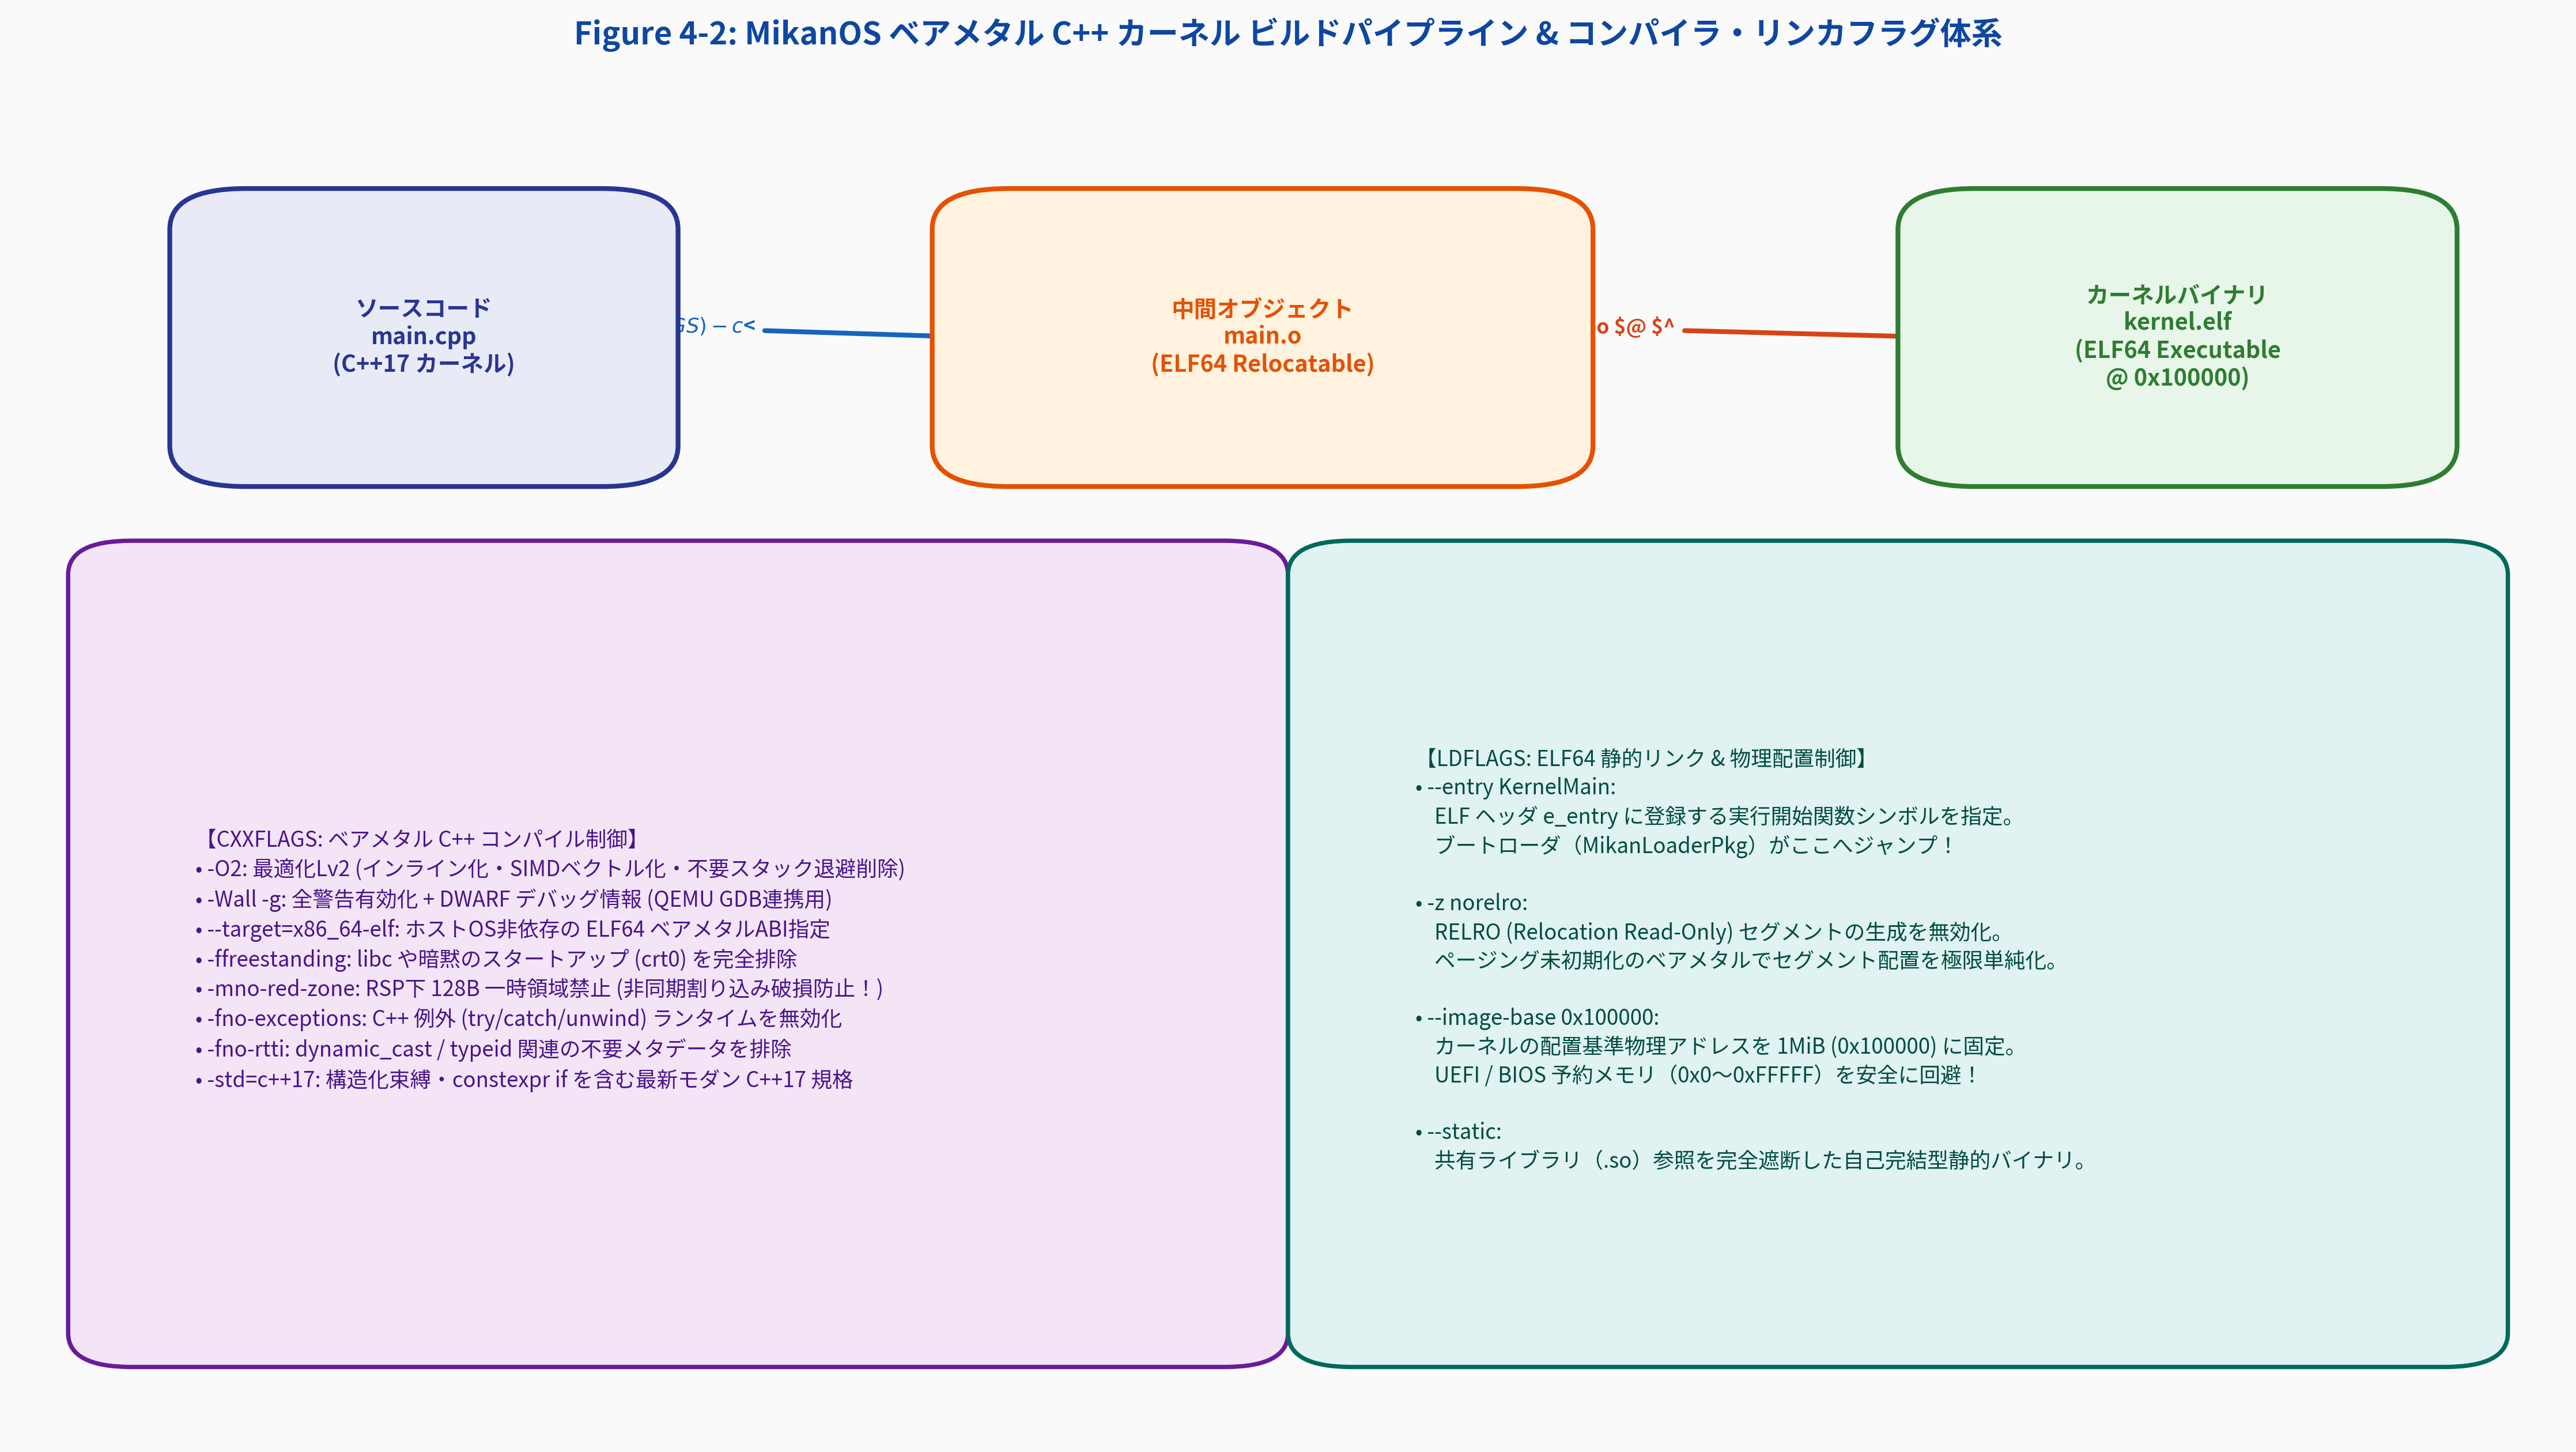

In [5]:
# === Figure 4-2: MikanOS ベアメタル C++ ビルドパイプライン & フラグ体系の可視化 ===
fig4_02_path = os.path.join(repo_root, "4/result/fig4_02_compiler_and_linker_flag_architecture.png")
plot_fig4_02_compiler_and_linker_flag_architecture(fig4_02_path)
display(Image(filename=fig4_02_path, width=950))


## 5. MikanOS ベアメタル C++ コンパイラ・リンカフラグの完全解読

`kernel/Makefile` に定義されている `CXXFLAGS` と `LDFLAGS` は、一般的な Linux アプリケーション開発用のフラグとは根本的に異なります。  
OS や標準ライブラリ（libc）が存在しない **「生（ベアメタル）の x86-64 CPU 上で直接実行されるカーネル」** を生成するための絶対要件が凝縮されています。

### 5.1 コンパイルフラグ（`CXXFLAGS`）の徹底解説

1. **`-O2` (Optimization Level 2)**:
   - ループ展開、インライン関数展開、レジスタ割り当ての最適化を施します。
   - 第3章 3.7節で検証した通り、フレームバッファのピクセル描画においてスタックへの冗長な読み書きを削減し、CPUのSIMDベクトル命令を活用して描画性能を劇的に引き上げます。
2. **`-Wall -g` (All Warnings & Debug Symbols)**:
   - `-Wall` は型変換の暗黙の切り捨てや未初期化ポインタの参照など、潜在的バグをコンパイル段階で警告します。ベアメタルOSではクラッシュ時にOSのエラーダイアログが出ないため、警告の撲滅が死活問題です。
   - `-g` は DWARF 形式のデバッグシンボルを埋め込み、QEMU と GDB を接続した際に関数名・変数名・行番号でのステップ実行を可能にします。
3. **`--target=x86_64-elf` (Cross-Compilation Target)**:
   - ホストOS（Linux/macOS/WSL）の実行環境に依存せず、純粋な 64ビット ELF 形式のバイナリを生成するよう Clang に指示します。
4. **`-ffreestanding` (Freestanding Environment)**:
   - ホスト環境の C/C++ 標準ライブラリ（glibc や musl）や暗黙のスタートアップコード（`crt0.o`）を一切リンクしない自立実行環境を宣言します。
   - `main()` 関数がプログラムの起点であるという標準Cの仮定を外し、カーネル独自の任意のエントリポイント（`KernelMain`）を許可します。
5. **`-mno-red-zone` (Disable Red Zone)**:
   - System V AMD64 ABI では、スタックポインタ `RSP` の下の 128 バイトを「レッドゾーン（Red Zone）」として一時変数退避に自由に使ってよい規約になっています。
   - しかし、OS カーネルではハードウェアからの **非同期割り込み（Interrupt）** がいつ発生するか分かりません。割り込みが発生すると、CPU ハードウェア自身が `RSP` の下に `RFLAGS`, `CS`, `RIP` 等をプッシュするため、レッドゾーンの内容が一瞬で破壊されます（第3章コラム3.1）。`-mno-red-zone` はこの致命的破壊を防ぐための **OSカーネル必須フラグ** です。
6. **`-fno-exceptions` & `-fno-rtti` (Suppress C++ Runtimes)**:
   - C++ の例外処理（`try`, `catch`, `throw`）は、スタック巻き戻し（Stack Unwinding）のための巨大なランタイムライブラリ（`libsupc++`）を必要とします。ベアメタルにはそれが存在しないため、`-fno-exceptions` で無効化します。
   - 同様に、実行時型情報（RTTI: `dynamic_cast`, `typeid`）も型メタデータ記述テーブルを必要とするため、`-fno-rtti` で抑制し、純粋な関数ポインタによる仮想関数テーブル（vtable）のみを使用します。
7. **`-std=c++17` (ISO C++17 Standard)**:
   - 構造化束縛（Structured Binding）、`constexpr if`、`std::string_view` など、型安全かつ表現力の高いモダン C++ の機能をフル活用するために指定します。

---

### 5.2 リンカフラグ（`LDFLAGS`）の徹底解説

1. **`--entry KernelMain` (Entry Point Symbol)**:
   - ELF バイナリのエントリポイント（実行開始アドレス）を指すシンボルとして `KernelMain` を指定します。
   - 第3章で実装したブートローダ（`MikanLoaderPkg`）は、カーネル ELF ヘッダの `e_entry` フィールドを読み取り、この関数へ直接ジャンプします。
2. **`-z norelro` (Disable Relocation Read-Only)**:
   - 現代の Linux ELF ではセキュリティ向上（GOT の改ざん防止）のため RELRO（Relocation Read-Only）セグメントが生成されますが、ベアメタルローダにとってはセグメント配置を複雑にするだけです。`-z norelro` でこれを無効化し、単純な `PT_LOAD` セグメントのみに絞ります。
3. **`--image-base 0x100000` (Kernel Base Address: 1MiB)**:
   - カーネルがロードされる物理基準アドレスを **1MiB (`0x100000`)** に固定します。
   - 第2章のメモリマップで確認した通り、`0x0` 〜 `0xFFFFF`（1MiB未満）はレガシー BIOS や UEFI の予約領域・VRAM・IVT 等で密集しています。1MiB より上の広大な空きRAM領域（`EfiConventionalMemory`）の先頭に正確に配置するために不可欠な設定です。
4. **`--static` (Static Linking)**:
   - 共有ライブラリ（`.so`）への動的リンク参照を完全に禁止し、すべてのコードとデータが1つのバイナリに完結した静的リンクバイナリを生成します。


In [6]:
# === Python CompilerFlagAnalyzer によるベアメタルビルドフラグの完全検査 ===
import pandas as pd
from common import CompilerFlagAnalyzer

flag_data = []
for f in CompilerFlagAnalyzer.FLAGS:
    flag_data.append({
        "フラグ名": f.flag,
        "カテゴリ": f.category,
        "目的・役割": f.purpose,
        "ベアメタルOSでの必須理由": f.baremetal_necessity,
        "省略時の致命的リスク": f.omission_risk
    })

df_flags = pd.DataFrame(flag_data)
pd.set_option('display.max_colwidth', None)
df_flags


,フラグ名,カテゴリ,目的・役割,ベアメタルOSでの必須理由,省略時の致命的リスク
0,-O2,Optimization,最適化レベル2（命令スケジューリング、レジスタ割り当て、インライン展開、SIMDベクトル化）,フレームバッファ描画やメモリ転送の性能を向上させ、不要なスタック読み書きを削減,極端な描画遅延や実行バイナリサイズの肥大化を招く
1,-Wall,Diagnostics,主要なコンパイラ警告（型不一致、未初期化変数、未使用シンボル等）の全網羅的有効化,OSカーネルにはデバッガが初動で存在しないため、未然に潜在バグを検出する最重要砦,未初期化ポインタ参照などのサイレントクラッシュを招く
2,-g,Diagnostics,DWARF形式のデバッグシンボル情報をバイナリ内に埋め込む,QEMU + GDB によるリモートデバッグ時に関数名や行番号、変数構造を直接可視化,逆アセンブル時に生のアドレスしか見えずデバッグ効率が激減する
3,--target=x86_64-elf,Target Architecture,ホストOS（Linux/macOS）非依存のベアメタル x86-64 ELF64 ABI をクロスコンパイルターゲットに指定,ホスト環境固有の共有ライブラリ依存や動的ローダ参照（.interp）を排除,ホストOS向けのLinuxバイナリが生成され、自作ブートローダで起動不能となる
4,-ffreestanding,Runtime Environment,OSや標準Cライブラリが存在しない自立（フリースタンディング）実行環境であることをコンパイラに宣言,main() を特別な関数とみなさず、暗黙のスタートアップコード（crt0.o）や標準ライブラリ呼び出しを禁止,"存在しない libc シンボル（memset, exit 等）の暗黙参照でリンクエラーが発生する"
5,-mno-red-zone,Target Architecture,System V AMD64 ABI 規定のスタックポインタ下 128 バイトの一時退避領域（Red Zone）の利用を禁止,非同期割り込み（Interrupt）発生時にCPUハードウェアがRSP下にレジスタをプッシュしてRed Zoneを破壊する事故を防ぐ,第7章以降で割り込みを有効化した瞬間にスタック破壊でカーネルが原因不明のパニックを起こす
6,-fno-exceptions,C++ Feature Suppression,"C++ 例外処理（try, catch, throw）およびスタック巻き戻し（Stack Unwinding）ランタイムを無効化",例外ハンドラテーブル（.eh_frame）や libsupc++ / libc++abi の複雑なランタイムがベアメタルに存在しない,リンク時に __gxx_personality_v0 等の巨大ランタイムシンボル未解決エラーが発生する
7,-fno-rtti,C++ Feature Suppression,"ランタイム型情報（RTTI: dynamic_cast, typeid）および型情報記述子構造体を無効化",型情報メタデータや vtable 内の RTTI 記述ポインタを省き、純粋な仮想関数ポインタのみに絞る,vtable から不要なランタイム型メタデータへの参照が発生しリンク不能となる
8,-std=c++17,Language Standard,ISO C++17 言語規格に準拠した最新機能（構造化束縛、constexpr if、std::byte 等）を有効化,高機能かつ型安全なモダンC++を活用した堅牢なカーネル設計を可能にする,古いC++規格に縛られ、型の安全機構やコード記述の表現力が著しく制約される
9,--entry KernelMain,Linker Specification,ELF 実行可能ファイルのエントリポイント（実行開始アドレス）シンボルを KernelMain に指定,ブートローダ（MikanLoaderPkg）が ELF ヘッダ e_entry を読み取って直接ジャンプ可能にする,リンカデフォルトの _start が期待され、リンク失敗または不正アドレスへジャンプする


In [7]:
# === C++20 スタンドアロン検証コード (src/ch04/make_sim.cpp) のコンパイル & 実行 ===
# ホスト側 GCC (g++) による C++20 単体テスト実行
import subprocess

cpp_src_path = os.path.join(repo_root, "src/ch04/make_sim.cpp")
cpp_bin_path = os.path.join(repo_root, "build/bin/ch04_make_sim")

print(f"C++20 検証コードのコンパイルとテスト実行: {cpp_src_path}")
res = subprocess.run([cpp_bin_path], capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print("STDERR:", res.stderr)
assert res.returncode == 0, "C++20 単体テストの実行に失敗しました"


C++20 検証コードのコンパイルとテスト実行: /home/student/Documents/GitHub/study-mikanos/src/ch04/make_sim.cpp
=== MikanOS Chapter 4.1: Make & Bare-metal Build Simulator (C++20) ===
[Test 1] Makefile rule and automatic variable expansion...
  -> PASSED
[Test 2] Dependency Graph topological sort & cycle detection...
  -> PASSED
[Test 3] Timestamp comparison & incremental build...
  -> PASSED
[Test 4] Phony target protection...
  -> PASSED
[Test 5] Compiler & Linker Flag specifications...
  -> PASSED
All C++20 Make & Bare-metal Build tests passed successfully!



## 6. 本節のまとめと確認演習問題・次節への展望

### 6.1 本節で学んだ重要知識の総括
1. **ビルド自動化の必然性**:
   - ソースコード分割に伴う再コンパイル時間の爆発を防ぐため、依存関係とタイムスタンプを比較して差分のみを再生成するインクリメンタルビルドが不可欠。
2. **Makefile の数学的基盤（DAG とトポロジカルソート）**:
   - ファイル依存関係を有向非巡回グラフとして表現し、深さ優先探索（DFS）で葉から根への評価順序を確定。
3. **タイムスタンプ比較則**:
   - `max(mtime(prerequisites)) > mtime(target)` またはターゲット不存在時にのみレシピを実行。
4. **擬似ターゲットと自動変数**:
   - `.PHONY` による同名ファイル衝突回避、`$@`, `$<`, `$^`, `$*` によるレシピ記述の抽象化・共通化。
5. **ベアメタル C++ ビルドフラグ**:
   - `-ffreestanding`（自立環境）、`-mno-red-zone`（割り込みスタック保護）、`--image-base 0x100000`（1MiB配置）など、OSカーネル特有のハードウェア制御要件。

---

### 6.2 理解度セルフチェック問題

- **問1**: カレントディレクトリに `clean` という空ファイルが存在するとき、Makefile に `.PHONY: clean` が書かれていないと `make clean` を実行した際どうなるか？その理由をタイムスタンプ比較則に基づいて説明せよ。
- **問2**: パターンルール `%.o: %.cpp Makefile` の必須条件に `Makefile` が含まれている理由を、`CXXFLAGS` を変更した場合の挙動に基づいて説明せよ。
- **問3**: x86-64 OS カーネルのコンパイルフラグに `-mno-red-zone` が絶対に欠かせない理由を、非同期割り込み発生時の CPU ハードウェアの動作とスタックポインタ `RSP` の関係から説明せよ。

---

### 6.3 次節への展望
ビルド自動化環境（`kernel/Makefile`）が整備されたことで、私たちは安心してカーネルのソースコードをモジュール分割できるようになりました。  
次節 **第4章 4.2「ピクセルを自在に描く」** では、ブートローダから渡されたフレームバッファ情報を `FrameBufferConfig` 構造体としてカプセル化し、Microsoft x64 ABI と System V AMD64 ABI のレジスタ渡し境界を乗り越えて、カーネルから画面全体に自由自在な矩形描画を実現していきます！
